In [28]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import csv

In [29]:
# Load csv
def load_csv_results_data(file_name):
    points_lf = []
    points_hf = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        for row in reader:
            print(row)
            points_lf.append(int(row[0]))
            points_hf.append(int(row[1]))
            model_error.append(float(row[2]))
            training_time.append(float(row[3]))
            evaluation_time.append(float(row[4]))
    return points_lf, points_hf, model_error, training_time, evaluation_time

In [30]:
# Function plotting

def plot_cokriging_data(
    points_lf,
    points_hf,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot(projection="3d")
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("Samples HF")
    ax.set_zlabel(label)

    if log_output:
        output = np.log10(output)

    ax.scatter(
        points_lf,
        points_hf,
        output,
        color=color,
        label=label,
    )


def plot_cokriging_data_slice(
    points_lf,
    points_hf,
    output,
    fix_lf=True,
    fix_value=10,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    x_values = []
    y_values = []
    if fix_lf:
        ax.set_xlabel("Samples HF")
        for i, val in enumerate(points_lf):
            if val == fix_value:
                x_values.append(points_hf[i])
                y_values.append(output[i])
    else:
        ax.set_xlabel("Samples_LF")
        for i, val in enumerate(points_hf):
            if val == fix_value:
                x_values.append(points_lf[i])
                y_values.append(output[i])
    ax.set_ylabel(label)

    if log_output:
        y_values = np.log10(y_values)

    print(x_values)
    ax.scatter(
        x_values,
        y_values,
        color=color,
        label=label,
    )
    return ax

In [ ]:
loaded_lf,loaded_hf,loaded_error,loaded_train_time,loaded_evaluation_time = load_csv_results_data('CokrigingResults_1D.csv')

['0', '4', '5.022183244742917', '0.004960199818015099', '0.0005598999559879303']
['0', '4', '4.455996607556095', '0.004888599971309304', '0.00041450001299381256']
['0', '4', '5.158202097644533', '0.00401380006223917', '0.00041999993845820427']
['2', '4', '4.058596047277122', '0.02809839998371899', '0.004098699893802404']
['2', '4', '4.513628374814454', '0.03892030008137226', '0.0014331999700516462']
['2', '4', '5.7166659699964555', '0.03562420001253486', '0.002430099993944168']
['4', '4', '8.76701832683161', '0.07141599990427494', '0.0016876999288797379']
['4', '4', '4.319813455968139', '0.11788390018045902', '0.001909700222313404']
['4', '4', '8.368113044827203', '0.078502899967134', '0.0019014999270439148']
['6', '4', '1.5757065151888707', '0.1042654998600483', '0.003205799963325262']
['6', '4', '3.723646069711769', '0.09414610010571778', '0.0028164000250399113']
['6', '4', '4.3565847671352085', '0.06592940003611147', '0.0026950999163091183']
['8', '4', '3.070573468883647', '0.047964

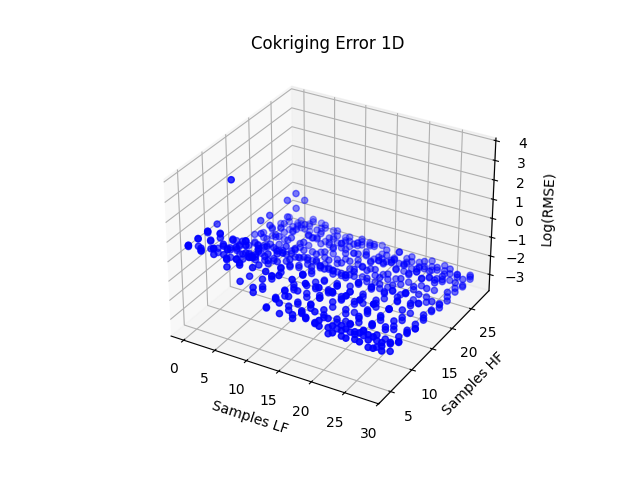

In [35]:
ax = plot_cokriging_data(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    label="Log(RMSE)",
    name="Cokriging Error 1D",
    log_output=True,
    color="blue",
)
plt.show()

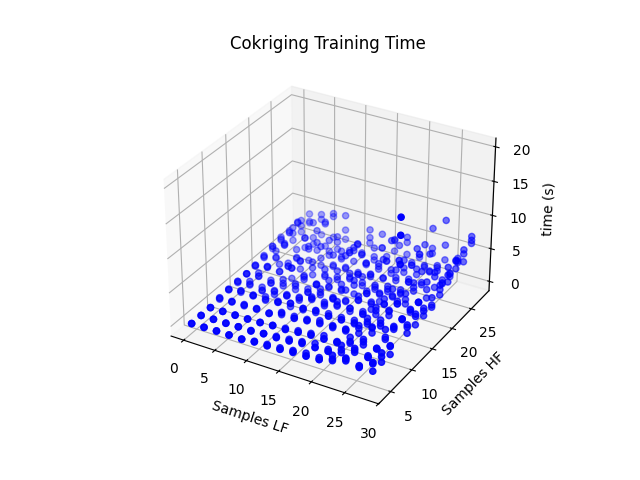

In [36]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_train_time, label="time (s)",name="Cokriging Training Time", color="blue"
)
plt.show()

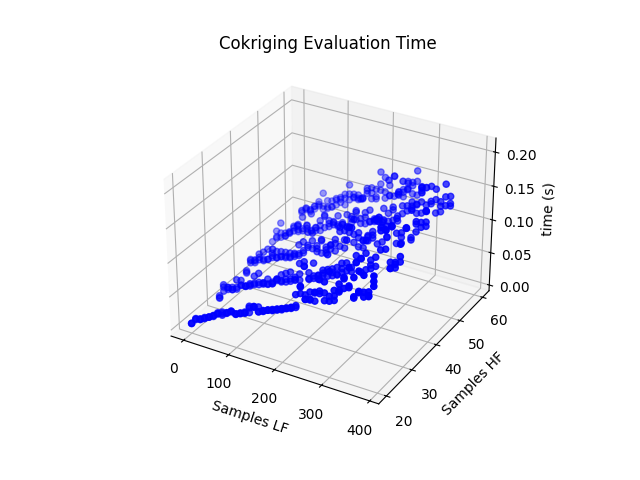

In [9]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_evaluation_time, label="time (s)",name="Cokriging Evaluation Time", color="blue"
)
plt.show()

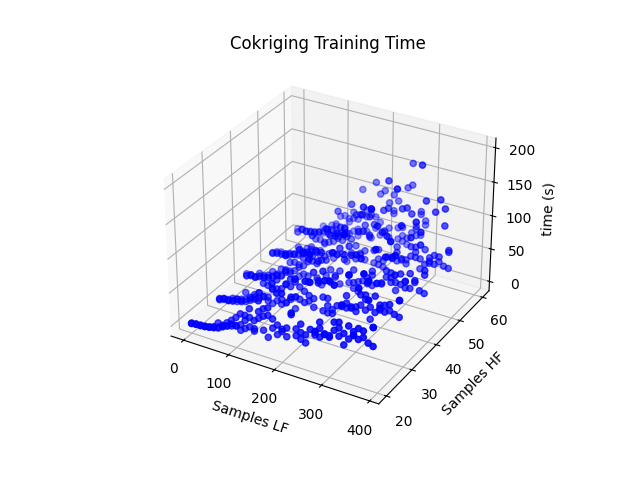

In [10]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_train_time, label="time (s)",name="Cokriging Training Time", color="blue"
)
plt.show()

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


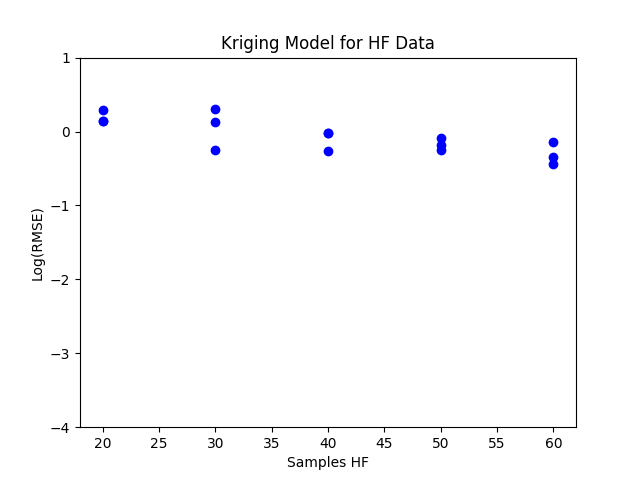

In [11]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=0, label="Log(RMSE)",name="Kriging Model for HF Data",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


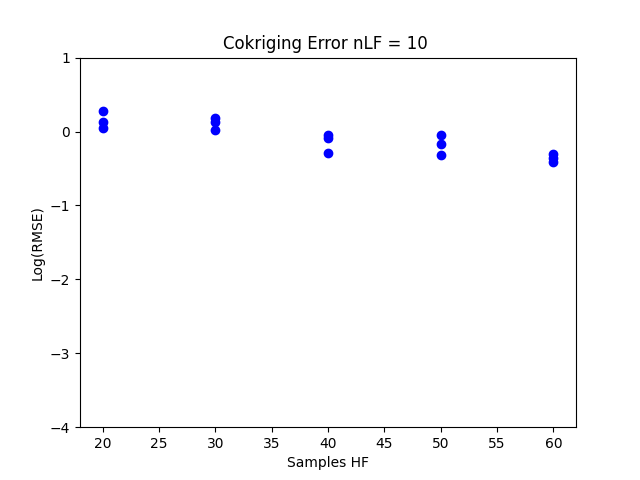

In [12]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=10, label="Log(RMSE)",name="Cokriging Error nLF = 10 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


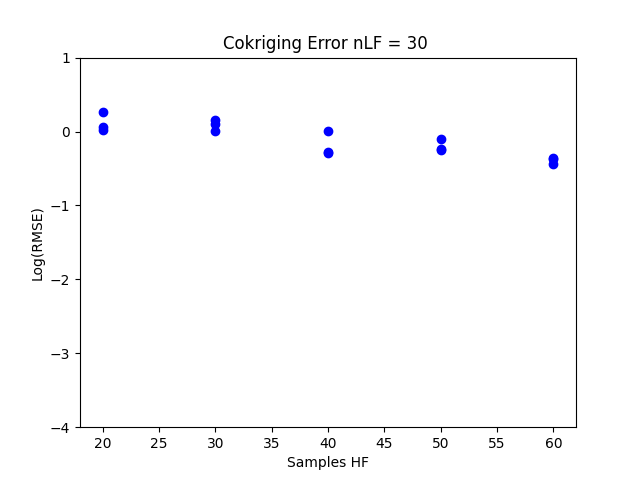

In [13]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=30, label="Log(RMSE)",name="Cokriging Error nLF = 30 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


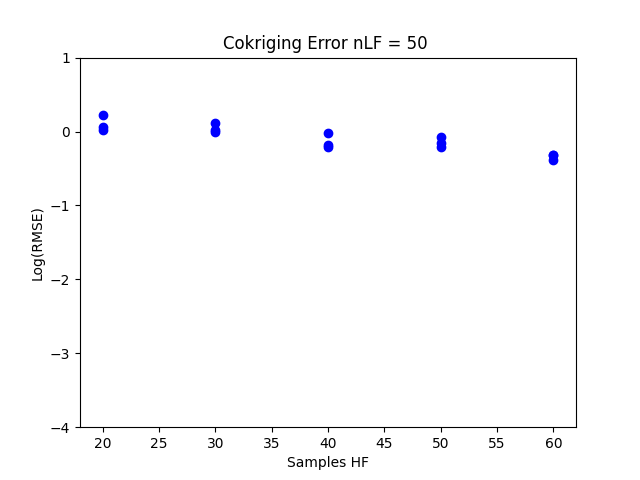

In [14]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=50, label="Log(RMSE)",name="Cokriging Error nLF = 50 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[]


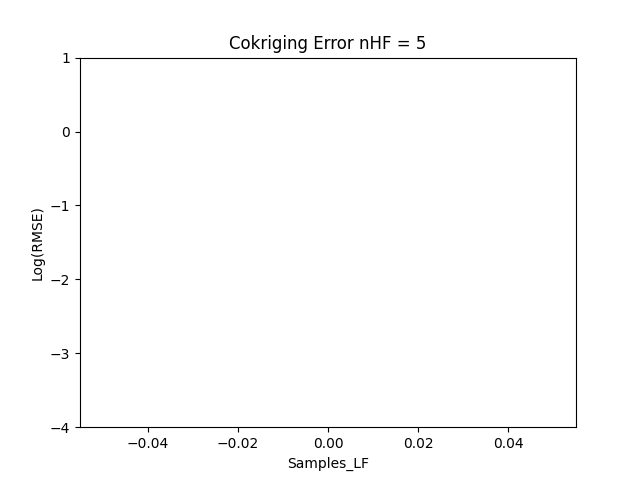

In [15]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=5,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 5",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[]


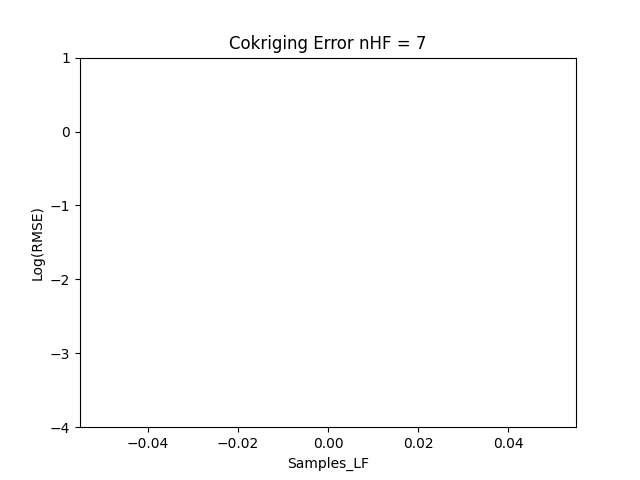

In [16]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=7,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 7",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[]


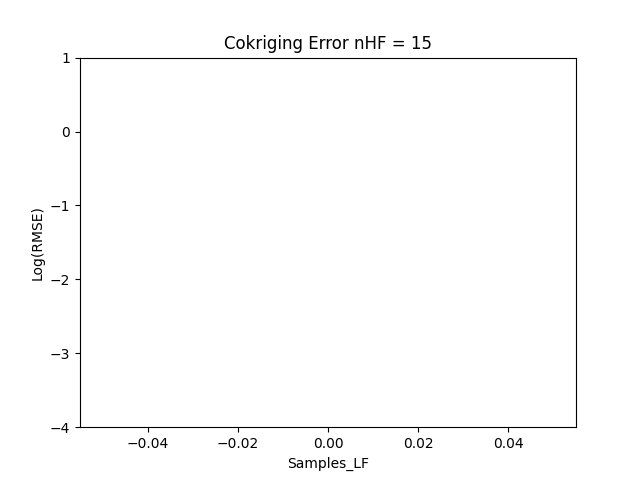

In [17]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=15,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 15",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[0, 0, 0, 10, 10, 10, 20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60, 70, 70, 70, 80, 80, 80, 90, 90, 90, 100, 100, 100, 110, 110, 110, 120, 120, 120, 130, 130, 130, 140, 140, 140, 150, 150, 150, 160, 160, 160, 170, 170, 170, 180, 180, 180, 190, 190, 190, 200, 200, 200, 210, 210, 210, 220, 220, 220, 230, 230, 230, 240, 240, 240, 250, 250, 250, 260, 260, 260, 270, 270, 270, 280, 280, 280, 290, 290, 290, 300, 300, 300, 310, 310, 310, 320, 320, 320, 330, 330, 330, 340, 340, 340, 350, 350, 350, 360, 360, 360, 370, 370, 370, 380, 380, 380, 390, 390, 390]


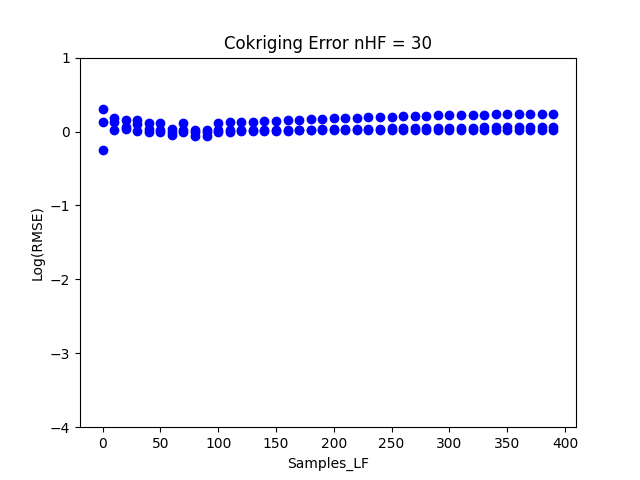

In [18]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=30,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 30",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)